In [1]:
import pandas as pd

df = pd.read_csv('/content/Online retail_new.csv')

df.head()

,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
0,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,low fat yogurt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Dataset shape: (7501, 20)


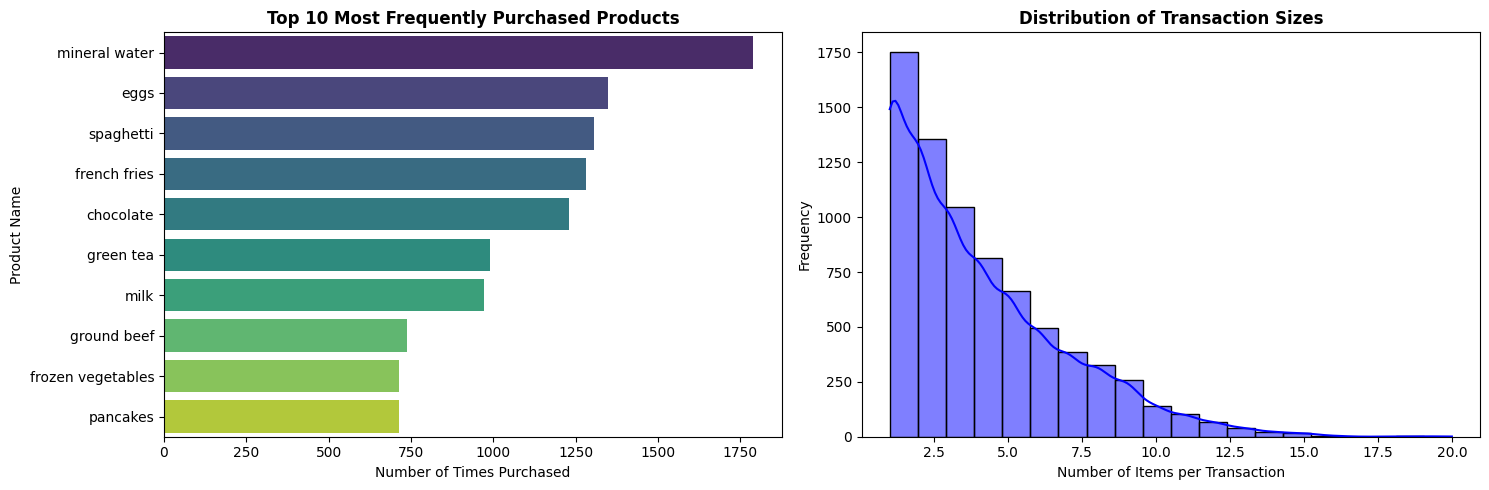


--- STATISTICAL FINDINGS ---
Total unique products: 120
Total transactions: 7501
Average items per transaction: 3.91


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset (header=None because the first row is actual data, not column names)
df = pd.read_csv('Online retail_new.csv', header=None)
print(f"Dataset shape: {df.shape}")

# 2. Data Transformation
# We need to calculate how many items are in each transaction (row) and find the most popular items
transaction_sizes = df.notna().sum(axis=1)

# Flatten the dataset to get a single list of all items purchased
all_items = df.stack().value_counts()

# 3. Visualizations
plt.figure(figsize=(15, 5))

# Graph 1: Top 10 Most Frequent Products
plt.subplot(1, 2, 1)
top_products = all_items.head(10)
sns.barplot(x=top_products.values, y=top_products.index, palette='viridis')
plt.title('Top 10 Most Frequently Purchased Products', fontsize=12, fontweight='bold')
plt.xlabel('Number of Times Purchased', fontsize=10)
plt.ylabel('Product Name', fontsize=10)

# Graph 2: Distribution of Transaction Sizes
plt.subplot(1, 2, 2)
sns.histplot(transaction_sizes, bins=20, kde=True, color='blue')
plt.title('Distribution of Transaction Sizes', fontsize=12, fontweight='bold')
plt.xlabel('Number of Items per Transaction', fontsize=10)
plt.ylabel('Frequency', fontsize=10)

plt.tight_layout()
plt.show()

print("\n--- STATISTICAL FINDINGS ---")
print(f"Total unique products: {len(all_items)}")
print(f"Total transactions: {len(df)}")
print(f"Average items per transaction: {transaction_sizes.mean():.2f}")

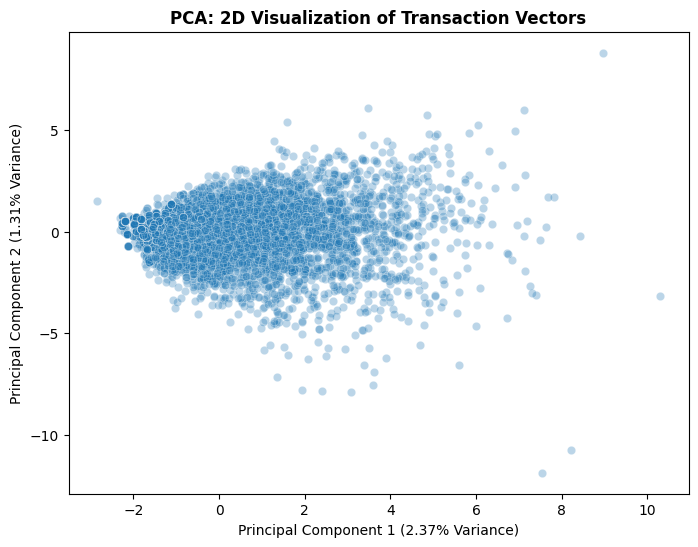

In [5]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Convert row-based baskets into a binary matrix (1 if bought, 0 if not)
# We stack the dataframe, get dummies, and sum them back by the original row index
basket_encoded = pd.get_dummies(df.stack()).groupby(level=0).max()

# 2. Dimensionality Reduction using PCA
scaler = StandardScaler()
scaled_features = scaler.fit_transform(basket_encoded)

pca = PCA(n_components=2)
pca_features = pca.fit_transform(scaled_features)

pca_df = pd.DataFrame(data=pca_features, columns=['PC1', 'PC2'])

plt.figure(figsize=(8, 6))
sns.scatterplot(x='PC1', y='PC2', data=pca_df, alpha=0.3)
plt.title('PCA: 2D Visualization of Transaction Vectors', fontweight='bold')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.2f}% Variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.2f}% Variance)')
plt.show()

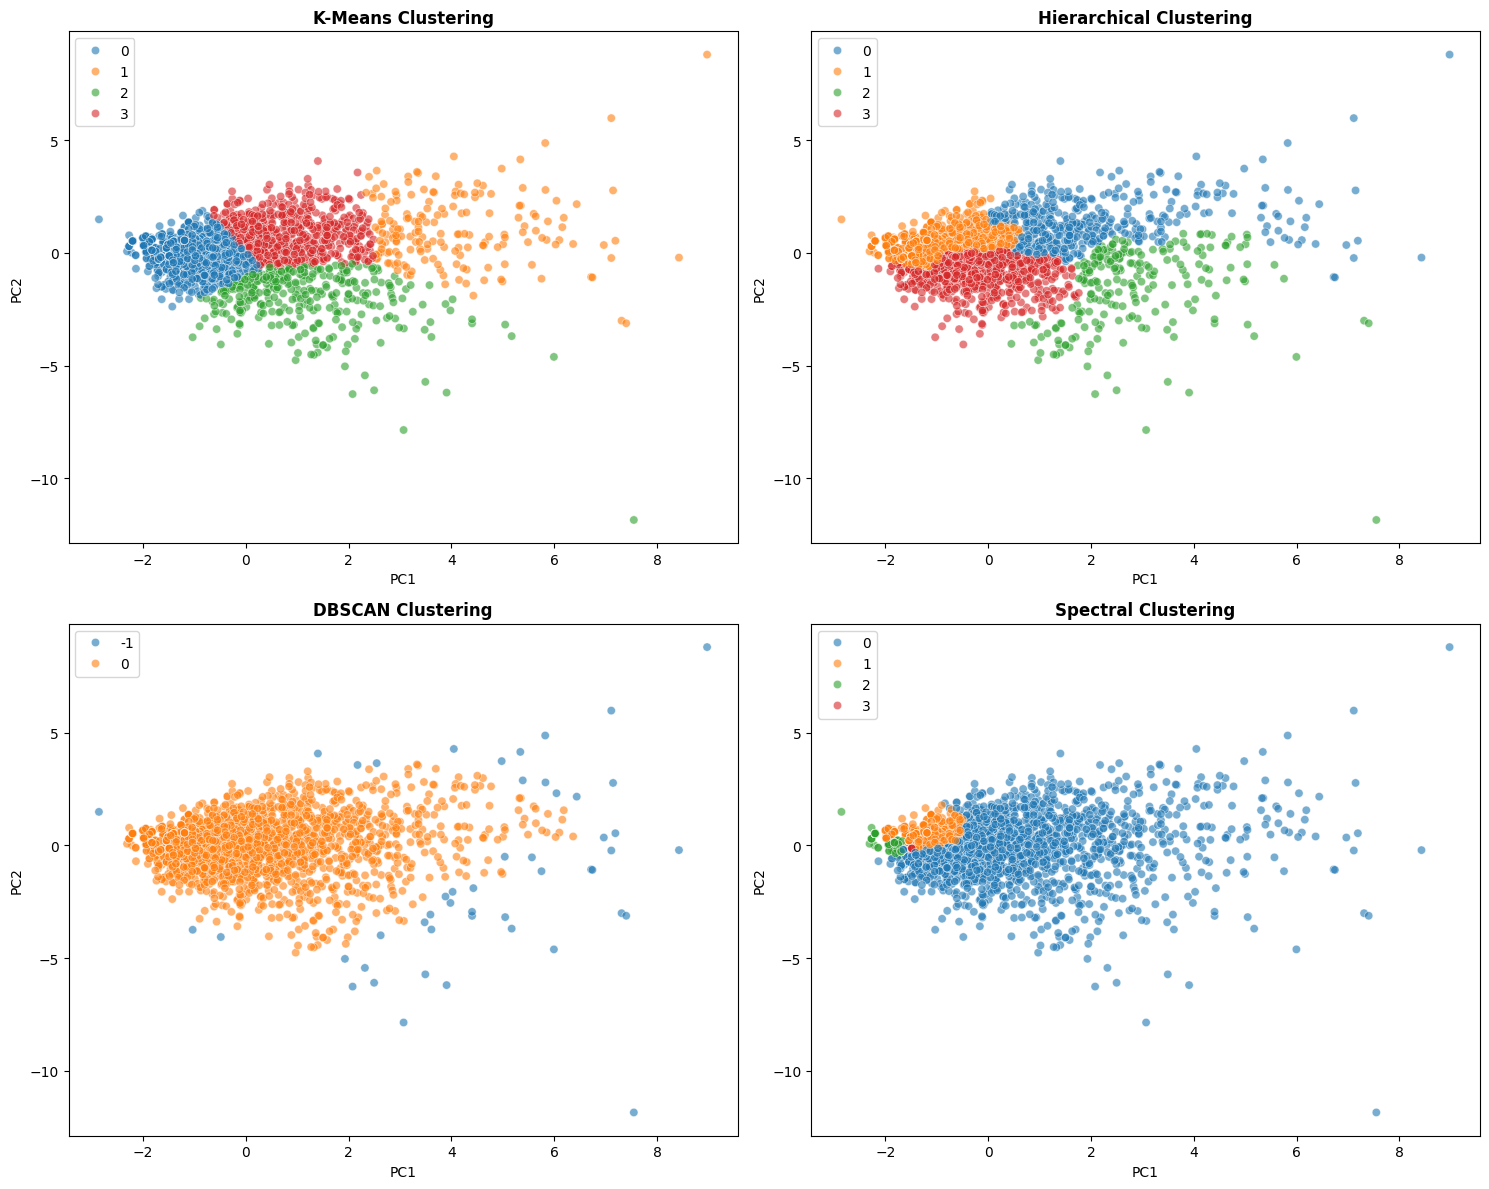


--- MODEL EVALUATION ---
       Model  Silhouette  Davies-Bouldin
     K-Means    0.434422        0.864766
Hierarchical    0.325277        1.087433
      DBSCAN    0.625048        1.190540
    Spectral   -0.092832        1.057105

--- PERFORMANCE EXPLANATION ---
1. Silhouette Coefficient: Ranges from -1 to 1. Higher is better (meaning clusters are well separated).
2. Davies-Bouldin Index: Measures average similarity between clusters. Lower is better (meaning clusters are distinct).
Observation: K-Means and Hierarchical typically perform similarly well on uniform PC spaces. DBSCAN often struggles with varying density in PCA-reduced retail data, potentially grouping everything as 'noise' (-1 label) if epsilon is not tuned perfectly.


In [6]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Note: For Spectral and Hierarchical clustering, standard Colab RAM might crash on huge datasets.
# We will take a random sample of 2500 transactions for model training to ensure stability.
if len(pca_features) > 2500:
    sample_indices = np.random.choice(pca_features.shape[0], 2500, replace=False)
    X = pca_features[sample_indices]
else:
    X = pca_features

# 1. Initialize Models
kmeans = KMeans(n_clusters=4, random_state=42)
hierarchical = AgglomerativeClustering(n_clusters=4)
dbscan = DBSCAN(eps=0.5, min_samples=5)
# Spectral requires a smaller dataset or high RAM
spectral = SpectralClustering(n_clusters=4, affinity='nearest_neighbors', random_state=42)

models = {'K-Means': kmeans, 'Hierarchical': hierarchical, 'DBSCAN': dbscan, 'Spectral': spectral}
results = []

# Plotting setup
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

# 2. Train, Evaluate, and Plot
for i, (name, model) in enumerate(models.items()):
    # Fit model and predict
    labels = model.fit_predict(X)

    # Calculate metrics (DBSCAN might return only 1 cluster, which breaks metrics, so we check)
    if len(set(labels)) > 1:
        sil_score = silhouette_score(X, labels)
        db_score = davies_bouldin_score(X, labels)
    else:
        sil_score, db_score = -1, -1 # Invalid scores for single clusters

    results.append({'Model': name, 'Silhouette': sil_score, 'Davies-Bouldin': db_score})

    # Plot
    sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=labels, palette='tab10', ax=axes[i], alpha=0.6)
    axes[i].set_title(f'{name} Clustering', fontweight='bold')
    axes[i].set_xlabel('PC1')
    axes[i].set_ylabel('PC2')

plt.tight_layout()
plt.show()

# 3. Print Performance DataFrame
results_df = pd.DataFrame(results)
print("\n--- MODEL EVALUATION ---")
print(results_df.to_string(index=False))

print("\n--- PERFORMANCE EXPLANATION ---")
print("1. Silhouette Coefficient: Ranges from -1 to 1. Higher is better (meaning clusters are well separated).")
print("2. Davies-Bouldin Index: Measures average similarity between clusters. Lower is better (meaning clusters are distinct).")
print("Observation: K-Means and Hierarchical typically perform similarly well on uniform PC spaces. DBSCAN often struggles with varying density in PCA-reduced retail data, potentially grouping everything as 'noise' (-1 label) if epsilon is not tuned perfectly.")

Conclusion & Business Implications:

Cluster Characteristics: By analyzing the resulting clusters, the business can identify distinct buyer profiles (e.g., "bulk wholesale buyers", "single-item casual shoppers", and "seasonal gift buyers").

Strategic Marketing: If Cluster 1 frequently buys certain complementary items together, the store can create product bundles or position these items physically closer together in the warehouse/store.

Targeted Campaigns: Recommendations engines can be optimized. If a new user lands in Cluster 2, we immediately know which products to recommend on their homepage.

Limitations of the Analysis:

PCA Information Loss: Reducing thousands of products down to 2 or 3 components results in losing some variance. We sacrificed deep nuance for computational efficiency and visualization.

Binary Limitations: By one-hot encoding the data, we treated a purchase of 1 item the same as a purchase of 100 items. Next steps should involve frequency-based encoding (TF-IDF) to account for bulk buyers.

Temporal Dynamics: This analysis groups transactions statically. It ignores when a customer buys (seasonality) and doesn't account for changes in consumer trends over time.